In [ ]:
import pandas as pd

df = pd.read_csv("KaggleV2-May-2016.csv")
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [ ]:
print(df.shape)
df.info()

(110527, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


In [ ]:
df["No-show"].value_counts(normalize=True)

,proportion
No-show,
No,0.798067
Yes,0.201933


In [ ]:
df = df.rename(columns={
    "Hipertension": "Hypertension",
    "Handcap": "Handicap",
    "SMS_received": "SMS",
    "No-show": "NoShow"
})

df["Missed"] = (df["NoShow"] == "Yes").astype(int)
df["Missed"].mean()

np.float64(0.20193255946510807)

In [ ]:
df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"])
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"])

df["WaitingDays"] = (df["AppointmentDay"].dt.normalize() - df["ScheduledDay"].dt.normalize()).dt.days
df["WaitingDays"].describe()

,WaitingDays
count,110527.000000
mean,10.183702
std,15.254996
min,-6.000000
25%,0.000000
50%,4.000000
75%,15.000000
max,179.000000


In [ ]:
print("Negative ages:", (df["Age"] < 0).sum())
print("Negative waiting days:", (df["WaitingDays"] < 0).sum())

Negative ages: 0
Negative waiting days: 0


In [ ]:
df = df[(df["Age"] >= 0) & (df["WaitingDays"] >= 0)]
print(df.shape)

(110521, 16)


In [ ]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[-1, 17, 34, 49, 64, 120],
                        labels=["0-17", "18-34", "35-49", "50-64", "65+"])

df["WaitGroup"] = pd.cut(df["WaitingDays"], bins=[-1, 0, 7, 30, 200],
                         labels=["Same day", "1-7 days", "8-30 days", "31+ days"])

df["Weekday"] = df["AppointmentDay"].dt.day_name()

df[["Age", "AgeGroup", "WaitingDays", "WaitGroup", "Weekday"]].head()

,Age,AgeGroup,WaitingDays,WaitGroup,Weekday
0,62,50-64,0,Same day,Friday
1,56,50-64,0,Same day,Friday
2,62,50-64,0,Same day,Friday
3,8,0-17,0,Same day,Friday
4,56,50-64,0,Same day,Friday


In [ ]:
df.groupby("WaitGroup", observed=True)["Missed"].mean()

,Missed
WaitGroup,
Same day,0.046471
1-7 days,0.241479
8-30 days,0.317220
31+ days,0.330025


In [ ]:
df.to_csv("appointments_clean.csv", index=False)

In [ ]:
for col in ["AgeGroup", "Gender", "SMS", "Scholarship", "Hypertension", "Diabetes"]:
    print(df.groupby(col, observed=True)["Missed"].mean().round(3), "\n")

AgeGroup
0-17     0.219
18-34    0.240
35-49    0.205
50-64    0.167
65+      0.155
Name: Missed, dtype: float64 

Gender
F    0.203
M    0.200
Name: Missed, dtype: float64 

SMS
0    0.167
1    0.276
Name: Missed, dtype: float64 

Scholarship
0    0.198
1    0.237
Name: Missed, dtype: float64 

Hypertension
0    0.209
1    0.173
Name: Missed, dtype: float64 

Diabetes
0    0.204
1    0.180
Name: Missed, dtype: float64 



In [ ]:
df.groupby(["WaitGroup", "SMS"], observed=True)["Missed"].mean().unstack().round(3)

In [ ]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["SMS"], df["Missed"])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
print("Chi-square:", round(chi2, 1), " p-value:", p)

Missed      0      1
SMS                 
0       62509  12530
1       25698   9784
Chi-square: 1768.0  p-value: 0.0


In [ ]:
from scipy.stats import mannwhitneyu

attended = df[df["Missed"] == 0]["WaitingDays"]
missed = df[df["Missed"] == 1]["WaitingDays"]

print("Median wait, attended:", attended.median())
print("Median wait, missed:", missed.median())

stat, p = mannwhitneyu(attended, missed)
print("p-value:", p)

Median wait, attended: 2.0
Median wait, missed: 11.0
p-value: 0.0


In [ ]:
import numpy as np
import statsmodels.formula.api as smf

crude = smf.logit("Missed ~ SMS", data=df).fit(disp=0)
adjusted = smf.logit("Missed ~ SMS + C(WaitGroup)", data=df).fit(disp=0)

print("Crude OR for SMS:", round(np.exp(crude.params["SMS"]), 2))
print("Adjusted OR for SMS:", round(np.exp(adjusted.params["SMS"]), 2))
print("95% CI (adjusted):", np.exp(adjusted.conf_int().loc["SMS"]).round(2).tolist())

Crude OR for SMS: 1.9
Adjusted OR for SMS: 0.82
95% CI (adjusted): [0.79, 0.85]


In [ ]:
model = smf.logit(
    "Missed ~ C(AgeGroup) + C(WaitGroup) + SMS + Gender + Scholarship"
    " + Hypertension + Diabetes + Alcoholism + C(Weekday, Treatment('Monday'))",
    data=df
).fit(disp=0)

results = pd.DataFrame({
    "OR": np.exp(model.params),
    "CI_low": np.exp(model.conf_int()[0]),
    "CI_high": np.exp(model.conf_int()[1]),
    "p": model.pvalues
}).round(3)

results

,OR,CI_low,CI_high,p
Intercept,0.056,0.052,0.060,0.000
C(AgeGroup)[T.18-34],1.050,1.004,1.097,0.033
C(AgeGroup)[T.35-49],0.825,0.787,0.865,0.000
C(AgeGroup)[T.50-64],0.601,0.570,0.633,0.000
C(AgeGroup)[T.65+],0.536,0.503,0.571,0.000
C(WaitGroup)[T.1-7 days],7.677,7.262,8.116,0.000
C(WaitGroup)[T.8-30 days],11.251,10.624,11.915,0.000
C(WaitGroup)[T.31+ days],12.467,11.662,13.327,0.000
Gender[T.M],1.046,1.012,1.082,0.009
"C(Weekday, Treatment('Monday'))[T.Friday]",0.969,0.921,1.019,0.218


In [ ]:
r = results.drop("Intercept").copy()
r.index = (r.index
    .str.replace(r"C\(Weekday, Treatment\('Monday'\)\)\[T\.(.*)\]", r"\1 (vs Monday)", regex=True)
    .str.replace(r"C\(AgeGroup\)\[T\.(.*)\]", r"Age \1 (vs 0-17)", regex=True)
    .str.replace(r"C\(WaitGroup\)\[T\.(.*)\]", r"Wait \1 (vs same day)", regex=True)
    .str.replace("Gender[T.M]", "Male (vs female)", regex=False))

plt.figure(figsize=(8, 7))
plt.errorbar(r["OR"], range(len(r)),
             xerr=[r["OR"] - r["CI_low"], r["CI_high"] - r["OR"]],
             fmt="o", capsize=3)
plt.yticks(range(len(r)), r.index)
plt.axvline(1, linestyle="--", color="grey")
plt.xscale("log")
plt.xlabel("Adjusted odds ratio (log scale)")
plt.title("Factors associated with missed outpatient appointments")
plt.tight_layout()
plt.savefig("forest_plot.png", dpi=200, bbox_inches="tight")
plt.show()

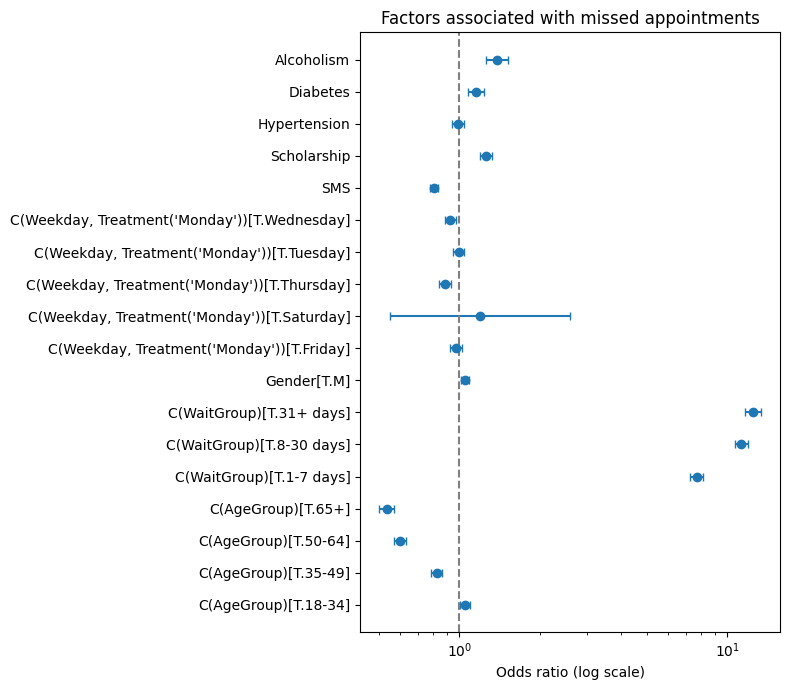

In [ ]:
import matplotlib.pyplot as plt

r = results.drop("Intercept")

plt.figure(figsize=(8, 7))
plt.errorbar(r["OR"], range(len(r)),
             xerr=[r["OR"] - r["CI_low"], r["CI_high"] - r["OR"]],
             fmt="o", capsize=3)
plt.yticks(range(len(r)), r.index)
plt.axvline(1, linestyle="--", color="grey")
plt.xscale("log")
plt.xlabel("Odds ratio (log scale)")
plt.title("Factors associated with missed appointments")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import glob

imd_file = [f for f in glob.glob("*.csv") if "imd" in f.lower()][0]
print("File:", imd_file)

nhs = pd.read_csv(imd_file)
print("Rows and columns:", nhs.shape)
print(nhs.columns.tolist())
nhs.head(10)

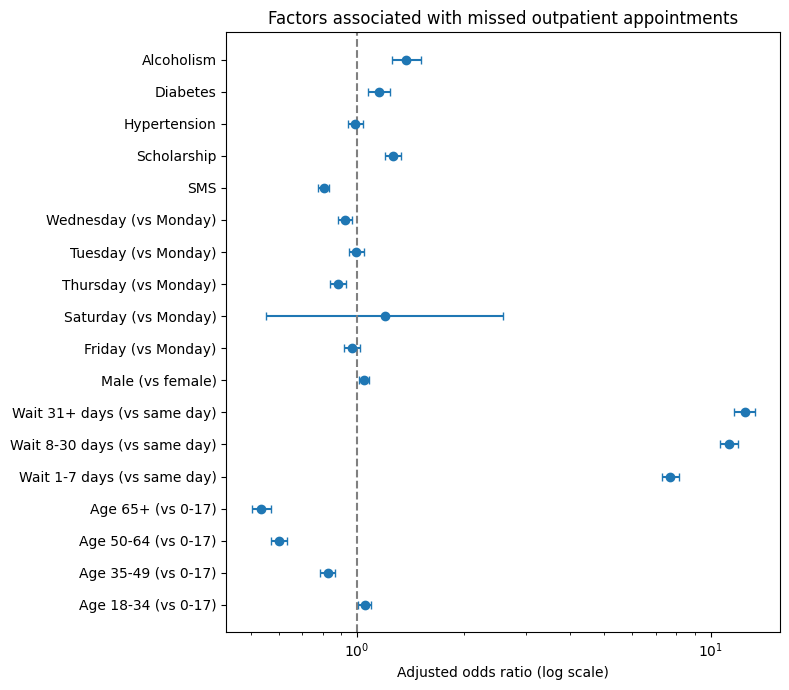

In [ ]:
r = results.drop("Intercept").copy()
r.index = (r.index
    .str.replace(r"C\(Weekday, Treatment\('Monday'\)\)\[T\.(.*)\]", r"\1 (vs Monday)", regex=True)
    .str.replace(r"C\(AgeGroup\)\[T\.(.*)\]", r"Age \1 (vs 0-17)", regex=True)
    .str.replace(r"C\(WaitGroup\)\[T\.(.*)\]", r"Wait \1 (vs same day)", regex=True)
    .str.replace("Gender[T.M]", "Male (vs female)", regex=False))

plt.figure(figsize=(8, 7))
plt.errorbar(r["OR"], range(len(r)),
             xerr=[r["OR"] - r["CI_low"], r["CI_high"] - r["OR"]],
             fmt="o", capsize=3)
plt.yticks(range(len(r)), r.index)
plt.axvline(1, linestyle="--", color="grey")
plt.xscale("log")
plt.xlabel("Adjusted odds ratio (log scale)")
plt.title("Factors associated with missed outpatient appointments")
plt.tight_layout()
plt.savefig("forest_plot.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
print(nhs["MEASURE_TYPE"].unique())

nhs["MEASURE"].str.split(" - ").str[0].value_counts()

['Activity by Ethnicity' 'Activity by IMD Decile']


,count
MEASURE,
Attended subsequent appointment,30
Attended but first/subsequent/tele unknown,30
Attended subsequent tele consultation,30
Percentage of all attendances,30
Attended appointment,19
All Attendances,19
Attended tele consultation,19
All attendances,11
Attended first appointment,11


In [ ]:
imd = nhs[nhs["MEASURE_TYPE"] == "Activity by IMD Decile"].copy()
imd[["Measure", "Group"]] = imd["MEASURE"].str.split(" - ", n=1, expand=True)

table = imd.pivot_table(index="Group", columns="Measure", values="MEASURE_VALUE")

attended_cols = [c for c in table.columns if c.startswith("Attended")]
table["Attended total"] = table[attended_cols].sum(axis=1)

table[["All attendances", "Attended total"]]

Measure,All attendances,Attended total
Group,,
LESS DEPRIVED 10%,10793290.0,10793290.0
LESS DEPRIVED 10-20%,11008175.0,11008175.0
LESS DEPRIVED 20-30%,11134523.0,11134523.0
LESS DEPRIVED 30-40%,11167381.0,11167381.0
LESS DEPRIVED 40-50%,11352200.0,11352200.0
MORE DEPRIVED 10-20%,11242959.0,11242959.0
MORE DEPRIVED 20-30%,11354423.0,11354423.0
MORE DEPRIVED 30-40%,11294332.0,11294332.0
MORE DEPRIVED 40-50%,11229225.0,11229225.0


In [ ]:
pla_file = [f for f in glob.glob("*.csv") if "pla" in f.lower()][0]
print("File:", pla_file)

pla = pd.read_csv(pla_file)
print("Rows and columns:", pla.shape)
print(pla.columns.tolist())
pla.head()

File: hosp-epis-stat-outp-pla-2024-25-tab.csv
Rows and columns: (45506, 8)
['REPORTING_PERIOD', 'GEOGRAPHY_LEVEL', 'ORGANISATION_CODE', 'ORGANISATION_DESCRIPTION', 'MEASURE_TYPE', 'MEASURE', 'MEASURE_VALUE', 'Unnamed: 7']


,REPORTING_PERIOD,GEOGRAPHY_LEVEL,ORGANISATION_CODE,ORGANISATION_DESCRIPTION,MEASURE_TYPE,MEASURE,MEASURE_VALUE,Unnamed: 7
0,2425,01.National,ENG,England,Attendance Summary by Gender,01.Attended-Female,65786591,NaN
1,2425,01.National,ENG,England,Attendance Summary by Gender,02.Attended-Male,47049643,NaN
2,2425,01.National,ENG,England,Attendance Summary by Gender,03.Attended-Unknown Gender,388919,NaN
3,2425,01.National,ENG,England,Attendance Summary by Gender,04.DNA-Female,4443789,NaN
4,2425,01.National,ENG,England,Attendance Summary by Gender,05.DNA-Male,3677257,NaN


In [ ]:
print(pla["GEOGRAPHY_LEVEL"].unique())
print()
print(pla["MEASURE_TYPE"].unique())

['01.National' '02.Commissioning Region' '03.Provider']

['Attendance Summary by Gender' 'Attendance Type'
 'Attendances by selected main specialty'
 'Attended Appointments by Age Group' 'Did not Attend by Age Group'
 'First Att from GP & Dental Practitioner refs by Waiting Time'
 'First Attendances by Outcome' 'First Attendances by Source of Referral']


In [ ]:
import pandas as pd
import glob

imd_file = [f for f in glob.glob("*.csv") if "imd" in f.lower()][0]
print("File:", imd_file)

nhs = pd.read_csv(imd_file)
print("Rows and columns:", nhs.shape)
print(nhs.columns.tolist())
nhs.head(10)

File: hosp-epis-stat-outp-eth-imd-dec-2024-25-data.csv
Rows and columns: (210, 4)
['REPORTING_PERIOD', 'MEASURE_TYPE', 'MEASURE', 'MEASURE_VALUE']


,REPORTING_PERIOD,MEASURE_TYPE,MEASURE,MEASURE_VALUE
0,2425,Activity by Ethnicity,All Attendances - African (Black or Black Brit...,2207375.0
1,2425,Activity by Ethnicity,All Attendances - All Ethnic Groups,113225153.0
2,2425,Activity by Ethnicity,All Attendances - Any other Asian background,2009458.0
3,2425,Activity by Ethnicity,All Attendances - Any other Black background,955038.0
4,2425,Activity by Ethnicity,All Attendances - Any other ethnic group,2886543.0
5,2425,Activity by Ethnicity,All Attendances - Any other Mixed background,789370.0
6,2425,Activity by Ethnicity,All Attendances - Any other White background,5701495.0
7,2425,Activity by Ethnicity,All Attendances - Bangladeshi (Asian or Asian ...,897017.0
8,2425,Activity by Ethnicity,All Attendances - British (White),67215444.0
9,2425,Activity by Ethnicity,All Attendances - Caribbean (Black or Black Br...,1253883.0


In [ ]:
etr = pd.read_csv("etr.csv", header=None)
print("Trusts file:", etr.shape)
display(etr.head())

lad_file = [f for f in glob.glob("*.csv") if "local authority" in f.lower()][0]
lad = pd.read_csv(lad_file)
print("Deprivation file:", lad.shape)
print(lad.columns.tolist())
display(lad.head())

Trusts file: (274, 27)


,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
0,G6V2S,NORTH LONDON NHS FOUNDATION TRUST,Y56,Z9B2Z,"4TH FLOOR, EAST WING",ST. PANCRAS HOSPITAL,4 ST. PANCRAS WAY,LONDON,NaN,NW1 0PE,...,NaN,NaN,NaN,NaN,1,NaN,H,NaN,NaN,NaN
1,K0N6A,THE ONLINE NHS TRUST,Y56,QKK,WELLINGTON HOUSE,133-155 WATERLOO ROAD,NaN,LONDON,NaN,SE1 8UG,...,NaN,NaN,NaN,NaN,1,NaN,H,NaN,NaN,NaN
2,R0A,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,Y62,QOP,COBBETT HOUSE,OXFORD ROAD,NaN,MANCHESTER,NaN,M13 9WL,...,0300 3309444,NaN,NaN,NaN,1,NaN,B,NaN,NaN,NaN
3,R0B,SOUTH TYNESIDE AND SUNDERLAND NHS FOUNDATION T...,Y63,QHM,SUNDERLAND ROYAL HOSPITAL,KAYLL ROAD,NaN,SUNDERLAND,NaN,SR4 7TP,...,NaN,NaN,NaN,NaN,1,NaN,A,NaN,NaN,NaN
4,R0C,PROJECT NIGHTINGALE NHS TRUST,Y56,QMF,ROYAL VICTORIA DOCK,1 WESTERN GATEWAY,NaN,LONDON,NaN,E16 1XL,...,NaN,NaN,NaN,NaN,1,NaN,H,NaN,NaN,NaN


Deprivation file: (296, 12)
['Local Authority District code (2024)', 'Local Authority District name (2024)', 'Index of Multiple Deprivation (IMD) Rank (where 1 is most deprived)', 'Income - Rank (where 1 is most deprived) ', 'Employment - Rank (where 1 is most deprived) ', 'Education, Skills and Training - Rank (where 1 is most deprived) ', 'Health Deprivation and Disability - Rank (where 1 is most deprived) ', 'Crime - Rank (where 1 is most deprived) ', 'Barriers to Housing and Services - Rank (where 1 is most deprived) ', 'Living Environment - Rank (where 1 is most deprived) ', 'IDACI - Rank (where 1 is most deprived) ', 'IDAOPI - Rank (where 1 is most deprived) ']


,Local Authority District code (2024),Local Authority District name (2024),Index of Multiple Deprivation (IMD) Rank (where 1 is most deprived),Income - Rank (where 1 is most deprived),Employment - Rank (where 1 is most deprived),"Education, Skills and Training - Rank (where 1 is most deprived)",Health Deprivation and Disability - Rank (where 1 is most deprived),Crime - Rank (where 1 is most deprived),Barriers to Housing and Services - Rank (where 1 is most deprived),Living Environment - Rank (where 1 is most deprived),IDACI - Rank (where 1 is most deprived),IDAOPI - Rank (where 1 is most deprived)
0,E06000001,Hartlepool,30,32,8,80,5,24,261,224,36,33
1,E06000002,Middlesbrough,21,19,12,27,13,4,156,133,19,44
2,E06000003,Redcar and Cleveland,62,65,27,105,35,49,236,187,60,74
3,E06000004,Stockton-on-Tees,119,114,86,147,40,96,267,257,127,115
4,E06000005,Darlington,103,110,80,122,54,73,272,136,114,114


In [ ]:
import requests

trusts = etr[[0, 1, 9]].copy()
trusts.columns = ["trust_code", "trust_name", "postcode"]

results = []
postcodes = trusts["postcode"].dropna().unique().tolist()

for i in range(0, len(postcodes), 100):
    response = requests.post("https://api.postcodes.io/postcodes",
                             json={"postcodes": postcodes[i:i+100]})
    for item in response.json()["result"]:
        found = item["result"]
        results.append({
            "postcode": item["query"],
            "lad_code": found["codes"]["admin_district"] if found else None,
            "lad_name": found["admin_district"] if found else None
        })

lookup = pd.DataFrame(results)
trusts = trusts.merge(lookup, on="postcode", how="left")

print("Trusts with no council match:", trusts["lad_code"].isna().sum())
trusts.head()

Trusts with no council match: 3


,trust_code,trust_name,postcode,lad_code,lad_name
0,G6V2S,NORTH LONDON NHS FOUNDATION TRUST,NW1 0PE,E09000007,Camden
1,K0N6A,THE ONLINE NHS TRUST,SE1 8UG,E09000022,Lambeth
2,R0A,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,M13 9WL,E08000003,Manchester
3,R0B,SOUTH TYNESIDE AND SUNDERLAND NHS FOUNDATION T...,SR4 7TP,E08000024,Sunderland
4,R0C,PROJECT NIGHTINGALE NHS TRUST,E16 1XL,E09000025,Newham


In [ ]:
# 1. DNA rate for every trust
prov = pla[(pla["GEOGRAPHY_LEVEL"] == "03.Provider") &
           (pla["MEASURE_TYPE"] == "Attendance Summary by Gender")].copy()
prov["value"] = pd.to_numeric(prov["MEASURE_VALUE"], errors="coerce")
prov["type"] = prov["MEASURE"].str.contains("DNA").map({True: "dna", False: "attended"})

rates = prov.pivot_table(index=["ORGANISATION_CODE", "ORGANISATION_DESCRIPTION"],
                         columns="type", values="value", aggfunc="sum").reset_index()
rates["booked"] = rates["attended"] + rates["dna"]
rates["dna_rate"] = rates["dna"] / rates["booked"]
rates = rates[rates["booked"] >= 10000]

# 2. Join to council area, then to deprivation
lad_code_col = lad.columns[0]
imd_col = [c for c in lad.columns if c.startswith("Index of Multiple")][0]

df_trust = (rates
    .merge(trusts[["trust_code", "lad_code", "lad_name"]],
           left_on="ORGANISATION_CODE", right_on="trust_code", how="inner")
    .merge(lad[[lad_code_col, imd_col]], left_on="lad_code",
           right_on=lad_code_col, how="inner"))
df_trust = df_trust.rename(columns={imd_col: "imd_rank"})

# 3. Group councils into 5 deprivation levels (1 = most deprived)
df_trust["imd_quintile"] = pd.qcut(df_trust["imd_rank"], 5,
    labels=["1 Most deprived", "2", "3", "4", "5 Least deprived"])

print("Trusts in analysis:", len(df_trust))
df_trust.groupby("imd_quintile", observed=True)["dna_rate"].agg(["count", "mean"]).round(3)

Trusts in analysis: 144


,count,mean
imd_quintile,,
1 Most deprived,29,0.068
2,31,0.064
3,26,0.048
4,29,0.056
5 Least deprived,29,0.052


In [ ]:
from scipy.stats import spearmanr

rho, p = spearmanr(df_trust["imd_rank"], df_trust["dna_rate"])
print("Spearman correlation:", round(rho, 2), "  p-value:", round(p, 4))

Spearman correlation: -0.32   p-value: 0.0001


In [ ]:
df_trust.to_csv("nhs_trust_dna_deprivation.csv", index=False)

In [ ]:
all_prov = prov.pivot_table(index=["ORGANISATION_CODE", "ORGANISATION_DESCRIPTION"],
                            columns="type", values="value", aggfunc="sum").reset_index()
all_prov["booked"] = all_prov["attended"] + all_prov["dna"]
print("All providers in NHS file:", len(all_prov))

small = all_prov[all_prov["booked"] < 10000]
print("1. Too small (<10,000 appointments):", len(small))

big = all_prov[all_prov["booked"] >= 10000]
not_trust = big[~big["ORGANISATION_CODE"].isin(trusts["trust_code"])]
print("2. Not in the NHS trust list:", len(not_trust))

matched = big.merge(trusts, left_on="ORGANISATION_CODE", right_on="trust_code")
no_imd = matched[~matched["lad_code"].isin(lad[lad_code_col])]
print("3. No deprivation match:", len(no_imd))

print("\nExamples of providers not in the trust list:")
display(not_trust[["ORGANISATION_CODE", "ORGANISATION_DESCRIPTION", "booked"]].head(10))

print("Trusts with no deprivation match:")
display(no_imd[["trust_name", "lad_code", "lad_name"]])

All providers in NHS file: 1286
1. Too small (<10,000 appointments): 397
2. Not in the NHS trust list: 156
3. No deprivation match: 3

Examples of providers not in the trust list:


type,ORGANISATION_CODE,ORGANISATION_DESCRIPTION,booked
3,8JE35,OVIVA UK LTD,21605.0
15,A4M8P,BUCKSHAW HOSPITAL,31175.0
26,AAH01,TETBURY HOSPITAL TRUST,16900.0
44,ACH01,WHITSTABLE MEDICAL PRACTICE,17680.0
62,AXG01,WILTSHIRE HEALTH & CARE (CHIPPENHAM),30360.0
64,AXG03,WARMINSTER COMMUNITY HOSPITAL,15115.0
69,AXG0I,MALMESBURY PRIMARY CARE CENTRE,11455.0
70,AXG0K,MELKSHAM COMMUNITY HOSPITAL,17905.0
75,AXG0T,TROWBRIDGE COMMUNITY HOSPITAL,18405.0
115,D2E5F,SPECSAVERS HEARCARE - LINCOLNSHIRE - NORTH HYK...,13415.0


Trusts with no deprivation match:


,trust_name,lad_code,lad_name
30,SHEFFIELD CHILDREN'S NHS FOUNDATION TRUST,E08000039,Sheffield
43,BARNSLEY HOSPITAL NHS FOUNDATION TRUST,E08000038,Barnsley
55,SHEFFIELD TEACHING HOSPITALS NHS FOUNDATION TRUST,E08000039,Sheffield


In [ ]:
print("4. Missing attended or DNA numbers:", all_prov["booked"].isna().sum())

name_col = lad.columns[1]
display(lad[lad[name_col].isin(["Sheffield", "Barnsley"])][[lad_code_col, name_col]])

4. Missing attended or DNA numbers: 589


,Local Authority District code (2024),Local Authority District name (2024)
242,E08000016,Barnsley
245,E08000019,Sheffield


In [ ]:
# Fix the 2024 boundary-change codes for Barnsley and Sheffield
trusts["lad_code"] = trusts["lad_code"].replace({
    "E08000038": "E08000016",
    "E08000039": "E08000019"
})

# Are any providers with missing numbers real NHS trusts?
missing = all_prov[all_prov["booked"].isna()]
missing_trusts = missing[missing["ORGANISATION_CODE"].isin(trusts["trust_code"])]
print("Providers with missing numbers that are NHS trusts:", len(missing_trusts))
display(missing_trusts.head(10))

Providers with missing numbers that are NHS trusts: 3


type,ORGANISATION_CODE,ORGANISATION_DESCRIPTION,attended,dna,booked
1149,RWK,EAST LONDON NHS FOUNDATION TRUST,87610.0,NaN,NaN
1168,RXY,KENT AND MEDWAY NHS AND SOCIAL CARE PARTNERSHI...,25.0,NaN,NaN
1175,RYY,KENT COMMUNITY HEALTH NHS FOUNDATION TRUST,135.0,NaN,NaN


In [ ]:
import pandas as pd
import glob

pla_file = [f for f in glob.glob("*.csv") if "pla" in f.lower()][0]
pla = pd.read_csv(pla_file)

age = pla[(pla["GEOGRAPHY_LEVEL"] == "01.National") &
          (pla["MEASURE_TYPE"].isin(["Did not Attend by Age Group",
                                     "Attended Appointments by Age Group"]))]

age[["MEASURE_TYPE", "MEASURE", "MEASURE_VALUE"]]

,MEASURE_TYPE,MEASURE,MEASURE_VALUE
17553,Attended Appointments by Age Group,00-09,6174060
17554,Attended Appointments by Age Group,10-19,6451290
17555,Attended Appointments by Age Group,20-29,9083601
17556,Attended Appointments by Age Group,30-39,13951706
17557,Attended Appointments by Age Group,40-49,10934979
17558,Attended Appointments by Age Group,50-59,15146392
17559,Attended Appointments by Age Group,60-69,18427556
17560,Attended Appointments by Age Group,70-79,19256758
17561,Attended Appointments by Age Group,80-89,11337578
17562,Attended Appointments by Age Group,90+,1966672


,dna_rate
MEASURE,
00-09,0.089
10-19,0.095
20-29,0.106
30-39,0.088
40-49,0.086
50-59,0.066
60-69,0.048
70-79,0.036
80-89,0.043


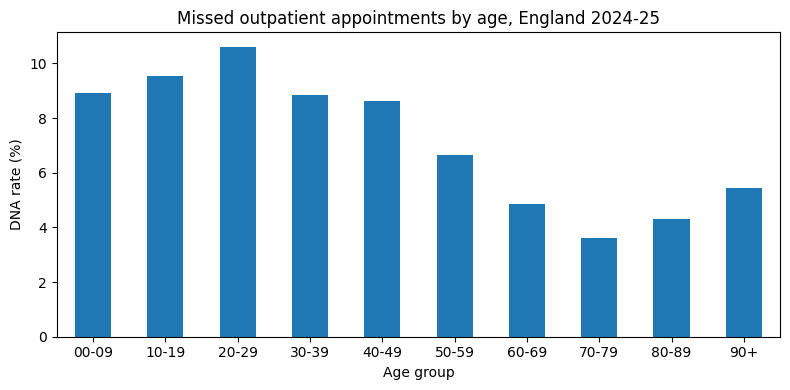

In [ ]:
import matplotlib.pyplot as plt

age = age.copy()
age["value"] = pd.to_numeric(age["MEASURE_VALUE"], errors="coerce")
age["type"] = age["MEASURE_TYPE"].map({
    "Did not Attend by Age Group": "dna",
    "Attended Appointments by Age Group": "attended"
})

nhs_age = age.pivot_table(index="MEASURE", columns="type", values="value").drop("Unknown")
nhs_age["dna_rate"] = nhs_age["dna"] / (nhs_age["attended"] + nhs_age["dna"])

display(nhs_age["dna_rate"].round(3))

(nhs_age["dna_rate"] * 100).plot(kind="bar", figsize=(8, 4))
plt.ylabel("DNA rate (%)")
plt.xlabel("Age group")
plt.title("Missed outpatient appointments by age, England 2024-25")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("nhs_dna_by_age.png", dpi=200)
plt.show()

In [ ]:
import sqlite3

con = sqlite3.connect("dna_project.db")

pd.read_csv("appointments_clean.csv").to_sql("appointments", con, if_exists="replace", index=False)
pd.read_csv("nhs_trust_dna_deprivation.csv").to_sql("trusts", con, if_exists="replace", index=False)
nhs_age.reset_index().to_sql("nhs_age", con, if_exists="replace", index=False)

def sql(query):
    return pd.read_sql(query, con)

print("Database ready with 3 tables: appointments, trusts, nhs_age")

Database ready with 3 tables: appointments, trusts, nhs_age


In [ ]:
sql("""
SELECT ORGANISATION_DESCRIPTION AS trust,
       lad_name AS area,
       ROUND(dna_rate * 100, 1) AS dna_rate_pct
FROM trusts
ORDER BY dna_rate DESC
LIMIT 10
""")

,trust,area,dna_rate_pct
0,NORTH STAFFORDSHIRE COMBINED HEALTHCARE NHS TRUST,Stoke-on-Trent,14.0
1,SUSSEX PARTNERSHIP NHS FOUNDATION TRUST,Worthing,12.4
2,OXLEAS NHS FOUNDATION TRUST,Dartford,11.0
3,KING'S COLLEGE HOSPITAL NHS FOUNDATION TRUST,Lambeth,10.3
4,LEICESTERSHIRE PARTNERSHIP NHS TRUST,Blaby,10.1
5,ALDER HEY CHILDREN'S NHS FOUNDATION TRUST,Liverpool,9.3
6,DONCASTER AND BASSETLAW TEACHING HOSPITALS NHS...,Doncaster,9.2
7,BEDFORDSHIRE HOSPITALS NHS FOUNDATION TRUST,Luton,9.2
8,LIVERPOOL UNIVERSITY HOSPITALS NHS FOUNDATION ...,Liverpool,9.1
9,BARTS HEALTH NHS TRUST,Tower Hamlets,9.0


In [ ]:
sql("""
SELECT
  CASE
    WHEN ORGANISATION_DESCRIPTION LIKE '%MENTAL%'
      OR ORGANISATION_DESCRIPTION LIKE '%PARTNERSHIP%'
      OR ORGANISATION_DESCRIPTION LIKE '%COMBINED HEALTHCARE%' THEN 'Mental health'
    WHEN ORGANISATION_DESCRIPTION LIKE '%COMMUNITY%' THEN 'Community'
    WHEN ORGANISATION_DESCRIPTION LIKE '%CHILDREN%' THEN 'Children''s'
    ELSE 'Acute / general'
  END AS trust_type,
  COUNT(*) AS trusts,
  ROUND(AVG(dna_rate) * 100, 1) AS avg_dna_pct
FROM trusts
GROUP BY trust_type
ORDER BY avg_dna_pct DESC
""")

,trust_type,trusts,avg_dna_pct
0,Mental health,7,7.9
1,Children's,4,6.9
2,Acute / general,127,5.7
3,Community,6,4.9


In [ ]:
sql("""
SELECT imd_quintile,
       COUNT(*) AS trusts,
       ROUND(AVG(dna_rate) * 100, 1) AS avg_dna_pct
FROM trusts
GROUP BY imd_quintile
ORDER BY imd_quintile
""")

,imd_quintile,trusts,avg_dna_pct
0,1 Most deprived,29,6.8
1,2,31,6.4
2,3,26,4.8
3,4,29,5.6
4,5 Least deprived,29,5.2


In [ ]:
sql("""
SELECT AgeGroup,
       COUNT(*) AS appointments,
       ROUND(AVG(Missed) * 100, 1) AS dna_pct
FROM appointments
GROUP BY AgeGroup
ORDER BY AgeGroup
""")

,AgeGroup,appointments,dna_pct
0,0-17,27378,21.9
1,18-34,24244,24.0
2,35-49,21864,20.5
3,50-64,22634,16.7
4,65+,14401,15.5


In [ ]:
lad_file = [f for f in glob.glob("*.csv") if "local authority" in f.lower()][0]
dep = pd.read_csv(lad_file)

def find_col(start):
    return [c for c in dep.columns if c.strip().startswith(start)][0]

dep = dep.rename(columns={
    dep.columns[0]: "lad_code",
    dep.columns[1]: "lad_name",
    find_col("Index of Multiple"): "imd_rank",
    find_col("Income"): "income_rank",
    find_col("Health Deprivation"): "health_rank"
})

dep[["lad_code", "lad_name", "imd_rank", "income_rank", "health_rank"]].to_sql(
    "deprivation", con, if_exists="replace", index=False)

print("New table 'deprivation' added:", len(dep), "council areas")

New table 'deprivation' added: 296 council areas


In [ ]:
sql("""
SELECT t.ORGANISATION_DESCRIPTION AS trust,
       d.lad_name AS area,
       ROUND(t.dna_rate * 100, 1) AS dna_pct,
       d.imd_rank,
       d.income_rank,
       d.health_rank
FROM trusts AS t
JOIN deprivation AS d
  ON t.lad_code = d.lad_code
ORDER BY t.dna_rate DESC
LIMIT 10
""")

,trust,area,dna_pct,imd_rank,income_rank,health_rank
0,NORTH STAFFORDSHIRE COMBINED HEALTHCARE NHS TRUST,Stoke-on-Trent,14.0,26,29,10
1,SUSSEX PARTNERSHIP NHS FOUNDATION TRUST,Worthing,12.4,185,153,132
2,OXLEAS NHS FOUNDATION TRUST,Dartford,11.0,163,166,154
3,KING'S COLLEGE HOSPITAL NHS FOUNDATION TRUST,Lambeth,10.3,70,54,114
4,LEICESTERSHIRE PARTNERSHIP NHS TRUST,Blaby,10.1,265,241,246
5,ALDER HEY CHILDREN'S NHS FOUNDATION TRUST,Liverpool,9.3,12,34,2
6,DONCASTER AND BASSETLAW TEACHING HOSPITALS NHS...,Doncaster,9.2,44,49,51
7,BEDFORDSHIRE HOSPITALS NHS FOUNDATION TRUST,Luton,9.2,33,8,87
8,LIVERPOOL UNIVERSITY HOSPITALS NHS FOUNDATION ...,Liverpool,9.1,12,34,2
9,BARTS HEALTH NHS TRUST,Tower Hamlets,9.0,20,3,65
